In [1]:
# conda vis2
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V04' / 'default'
ITERATIONS = EXPERIMENT / 'iterations'
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
FIGURE_OUT = PROJECT_ROOT / 'figures'

import sys
sys.path.append(str(PROJECT_ROOT))

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import at3d
import glob

savefig = True
fig_version = 'V03'

In [2]:
def CAMP2Ex_insitu_compare(cloud, p3, f, ax, thresh=0):
    ax.grid()
    pristine = p3.aerosols.data == 0
    trans = p3.aerosols.data == 1
    polluted = p3.aerosols.data == 2

    prist_color = 'tab:green'
    trans_color = 'tab:gray'
    poll_color = 'tab:brown'
    
    cloud_cond = cloud.ext_ravel.data > thresh
    ext_cloud = cloud.ext_ravel.data[cloud_cond]
    z_cloud = cloud.Z.data[cloud_cond]
    # ax.scatter(ext_cloud, z_cloud*1000)

    positions = []
    ext_box = []
    for z in cloud.z.data:
        ext_box.append(ext_cloud[z_cloud == z])
        positions.append(int(z*1000))
    ax.boxplot(ext_box, positions=positions, widths=80, vert=False, manage_ticks=False)

    # ax.scatter(p3.ext_km.data[pristine], p3.GPS_Altitude[pristine], c=prist_color, label='pristine')
    # ax.scatter(p3.ext_km.data[trans], p3.GPS_Altitude[trans], c=trans_color, label='trans')
    # ax.scatter(p3.ext_km.data[polluted], p3.GPS_Altitude[polluted], c=poll_color, label='polluted')
    ax.scatter(p3.ext_km.data[pristine], p3.GPS_Altitude[pristine], c='tab:blue', s=16, label='NASA P3')
    ax.scatter(p3.ext_km.data[trans], p3.GPS_Altitude[trans], c='tab:blue', s=16)
    ax.scatter(p3.ext_km.data[polluted], p3.GPS_Altitude[polluted], c='tab:blue', s=16)

    ax.set_xlabel('Extinction (1/km)')
    ax.set_ylabel('Altitude (m)')
    # ax.grid()
    # ax.legend()
    ax.set_xscale('log')

In [3]:
p3_file = INTERIM_DATA / 'CAMP2Ex_SPEC_RF17_preprocessed.nc'
p3 = xr.load_dataset(p3_file)
p3 = p3.sel(time=slice('2019-10-02T00:00:00', '2019-10-02T01:50:00'))

iter_files = sorted(ITERATIONS.glob('iter*.nc'))
sensors, solvers, rte_grid = at3d.util.load_forward_model(iter_files[-1])
cloud = solvers[0.67].medium['cloud']
cloud = cloud.sel(x=slice(2, 15), y=slice(5, 10))
X, Y, Z = np.meshgrid(cloud.x.data, cloud.y.data, cloud.z.data, indexing='ij')
cloud = cloud.assign_coords(Z=np.ravel(Z))
cloud['ext_ravel'] = (['Z'], np.ravel(cloud.extinction.data))

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '51'. Max cell optical depth: '3.0740342140197754'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


## Figure 11: CAMP2Ex in-situ comparison

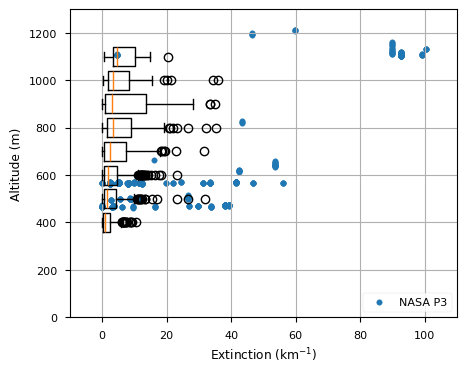

In [4]:
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 1, figsize=(5, 4))
CAMP2Ex_insitu_compare(cloud, p3, f, ax, thresh=0)
ax.set_xscale('linear')
ax.set_xlim([-10, 110])
ax.set_ylim([0, 1300])
ax.set_xlabel(r'Extinction (km$^{-1}$)')
ax.legend(loc='lower right')

plt.savefig(
    FIGURE_OUT / '{}_figure11_insitu_comparison.png'.format(fig_version),
    format='png',
    dpi=300,
    bbox_inches='tight',
    transparent=False
)